In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
df=pd.read_csv("music_features.csv")
df.shape
df.sample(5)

,song_id,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
5083,jazz.00009.wav,66150,0.274053,0.084140,0.075618,0.000691,1043.146006,8.687004e+04,1530.254717,85865.819342,...,41.551334,-2.254539,68.119606,-2.056478,36.896152,2.988356,82.052635,-4.926671,85.021970,jazz
5552,jazz.00057.wav,66150,0.172696,0.084244,0.108437,0.002750,1276.096388,5.782062e+04,1845.062808,134691.928730,...,25.451350,-8.772265,54.213913,-12.772853,51.935870,-11.759435,58.003784,-12.965003,44.431340,jazz
7205,pop.00022.wav,66150,0.326789,0.090529,0.177534,0.006082,3230.241562,6.057444e+05,3261.140071,108303.376506,...,31.818182,-1.486856,48.097370,-5.207882,48.971725,-2.193686,31.153740,-2.704737,51.679640,pop
7556,pop.00057.wav,66150,0.529667,0.086820,0.331488,0.019923,3680.439872,1.012722e+06,3277.500034,131435.242280,...,113.289825,11.062616,193.111820,8.438751,93.529100,0.433659,106.070760,-0.739835,142.008010,pop
2906,country.00091.wav,66150,0.297112,0.084324,0.078942,0.000924,1820.222991,1.278102e+05,1740.263379,78398.312583,...,48.919765,-16.513432,64.802170,-5.818159,55.410990,-0.146565,78.577930,-8.569535,44.836983,country


In [3]:
df["label"].value_counts()

label
blues        1000
metal        1000
pop          1000
reggae       1000
disco         999
rock          999
classical     998
hiphop        998
country       997
jazz          990
Name: count, dtype: int64

In [4]:
df.isnull().sum()

song_id                    0
length                     0
chroma_stft_mean           0
chroma_stft_var            0
rms_mean                   0
rms_var                    0
spectral_centroid_mean     0
spectral_centroid_var      0
spectral_bandwidth_mean    0
spectral_bandwidth_var     0
rolloff_mean               0
rolloff_var                0
zero_crossing_rate_mean    0
zero_crossing_rate_var     0
harmony_mean               0
harmony_var                0
perceptr_mean              0
perceptr_var               0
tempo                      0
mfcc1_mean                 0
mfcc1_var                  0
mfcc2_mean                 0
mfcc2_var                  0
mfcc3_mean                 0
mfcc3_var                  0
mfcc4_mean                 0
mfcc4_var                  0
mfcc5_mean                 0
mfcc5_var                  0
mfcc6_mean                 0
mfcc6_var                  0
mfcc7_mean                 0
mfcc7_var                  0
mfcc8_mean                 0
mfcc8_var     

In [5]:
df.dtypes

song_id                        str
length                       int64
chroma_stft_mean           float64
chroma_stft_var            float64
rms_mean                   float64
rms_var                    float64
spectral_centroid_mean     float64
spectral_centroid_var      float64
spectral_bandwidth_mean    float64
spectral_bandwidth_var     float64
rolloff_mean               float64
rolloff_var                float64
zero_crossing_rate_mean    float64
zero_crossing_rate_var     float64
harmony_mean               float64
harmony_var                float64
perceptr_mean              float64
perceptr_var               float64
tempo                      float64
mfcc1_mean                 float64
mfcc1_var                  float64
mfcc2_mean                 float64
mfcc2_var                  float64
mfcc3_mean                 float64
mfcc3_var                  float64
mfcc4_mean                 float64
mfcc4_var                  float64
mfcc5_mean                 float64
mfcc5_var           

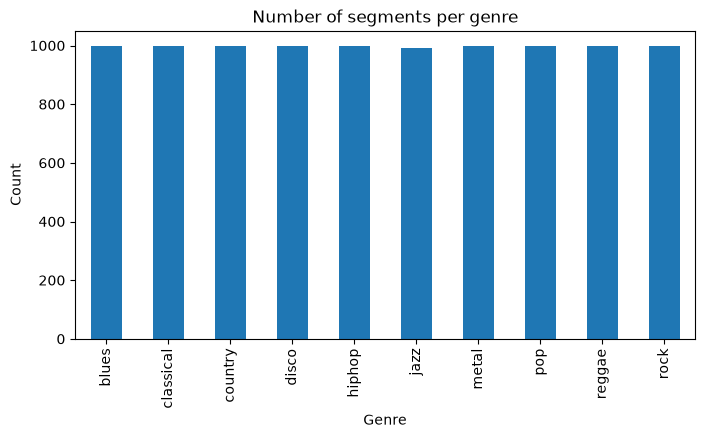

In [6]:
df["label"].value_counts().sort_index().plot(kind="bar",figsize=(8,4))
plt.title("Number of segments per genre")
plt.xlabel("Genre")
plt.ylabel("Count")
plt.show()

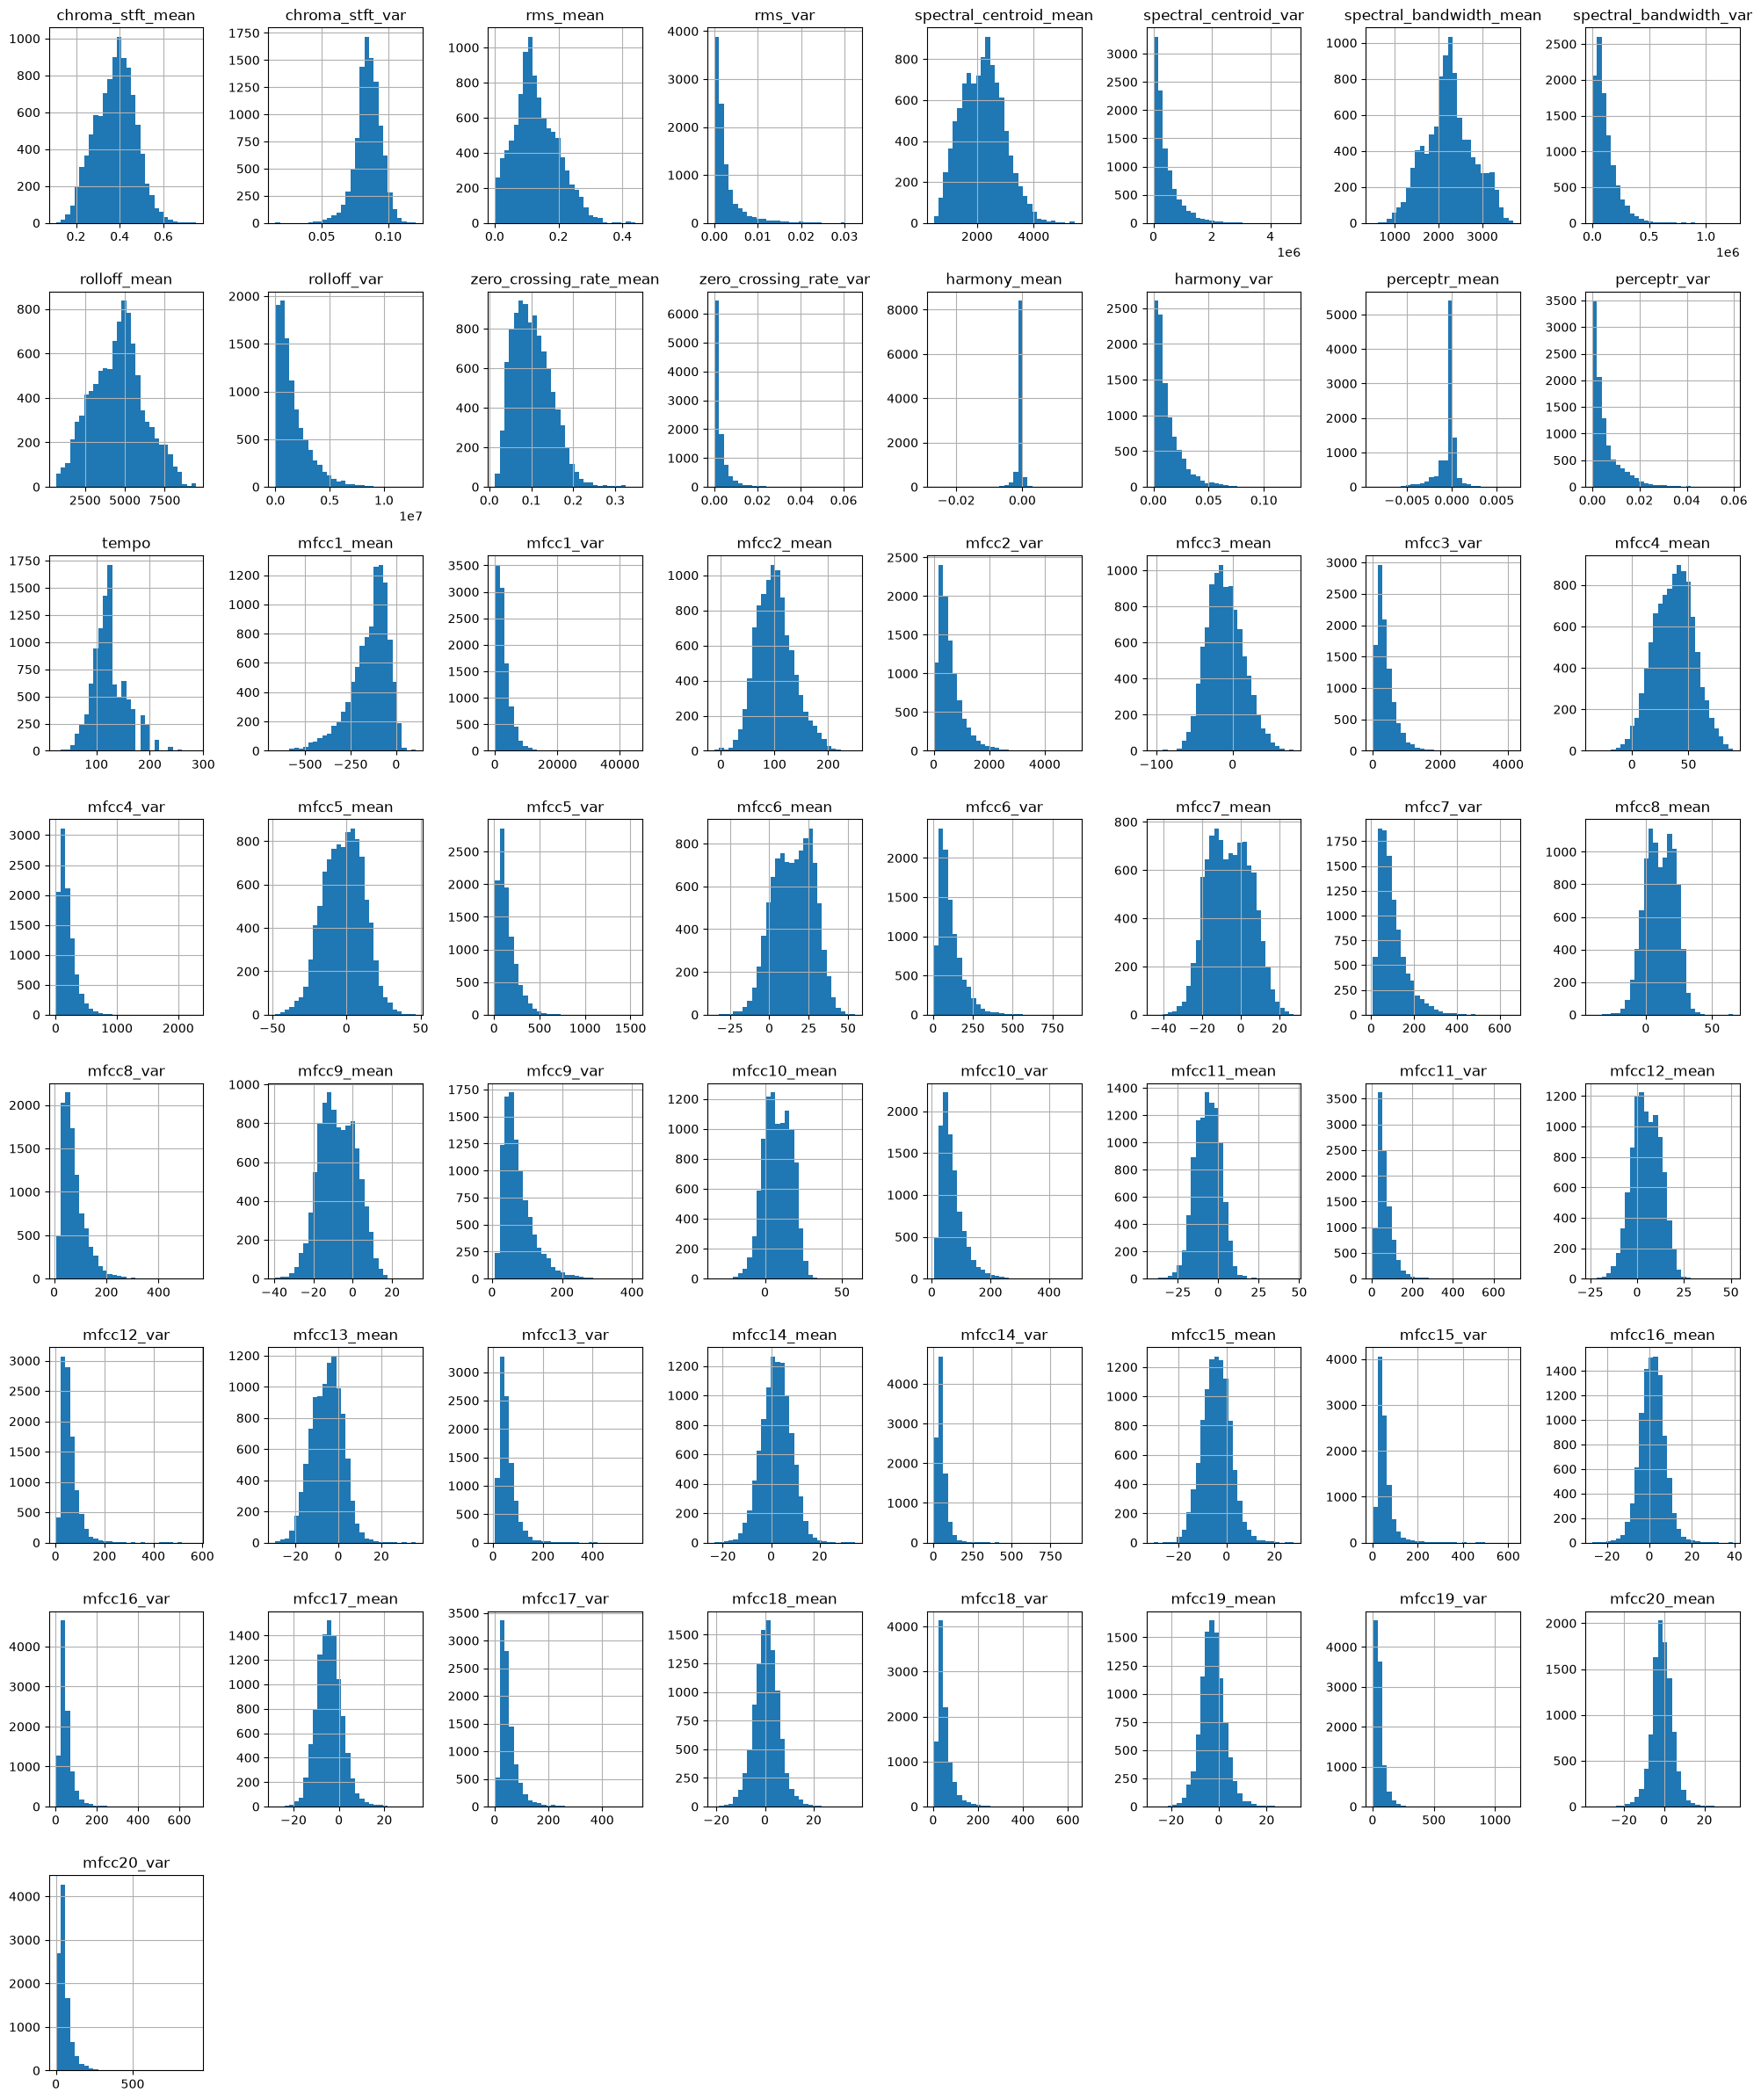

In [7]:
features = df.drop(columns=["song_id", "label", "length"])

features.hist(bins=30, figsize=(20, 24))
plt.tight_layout()
plt.show()

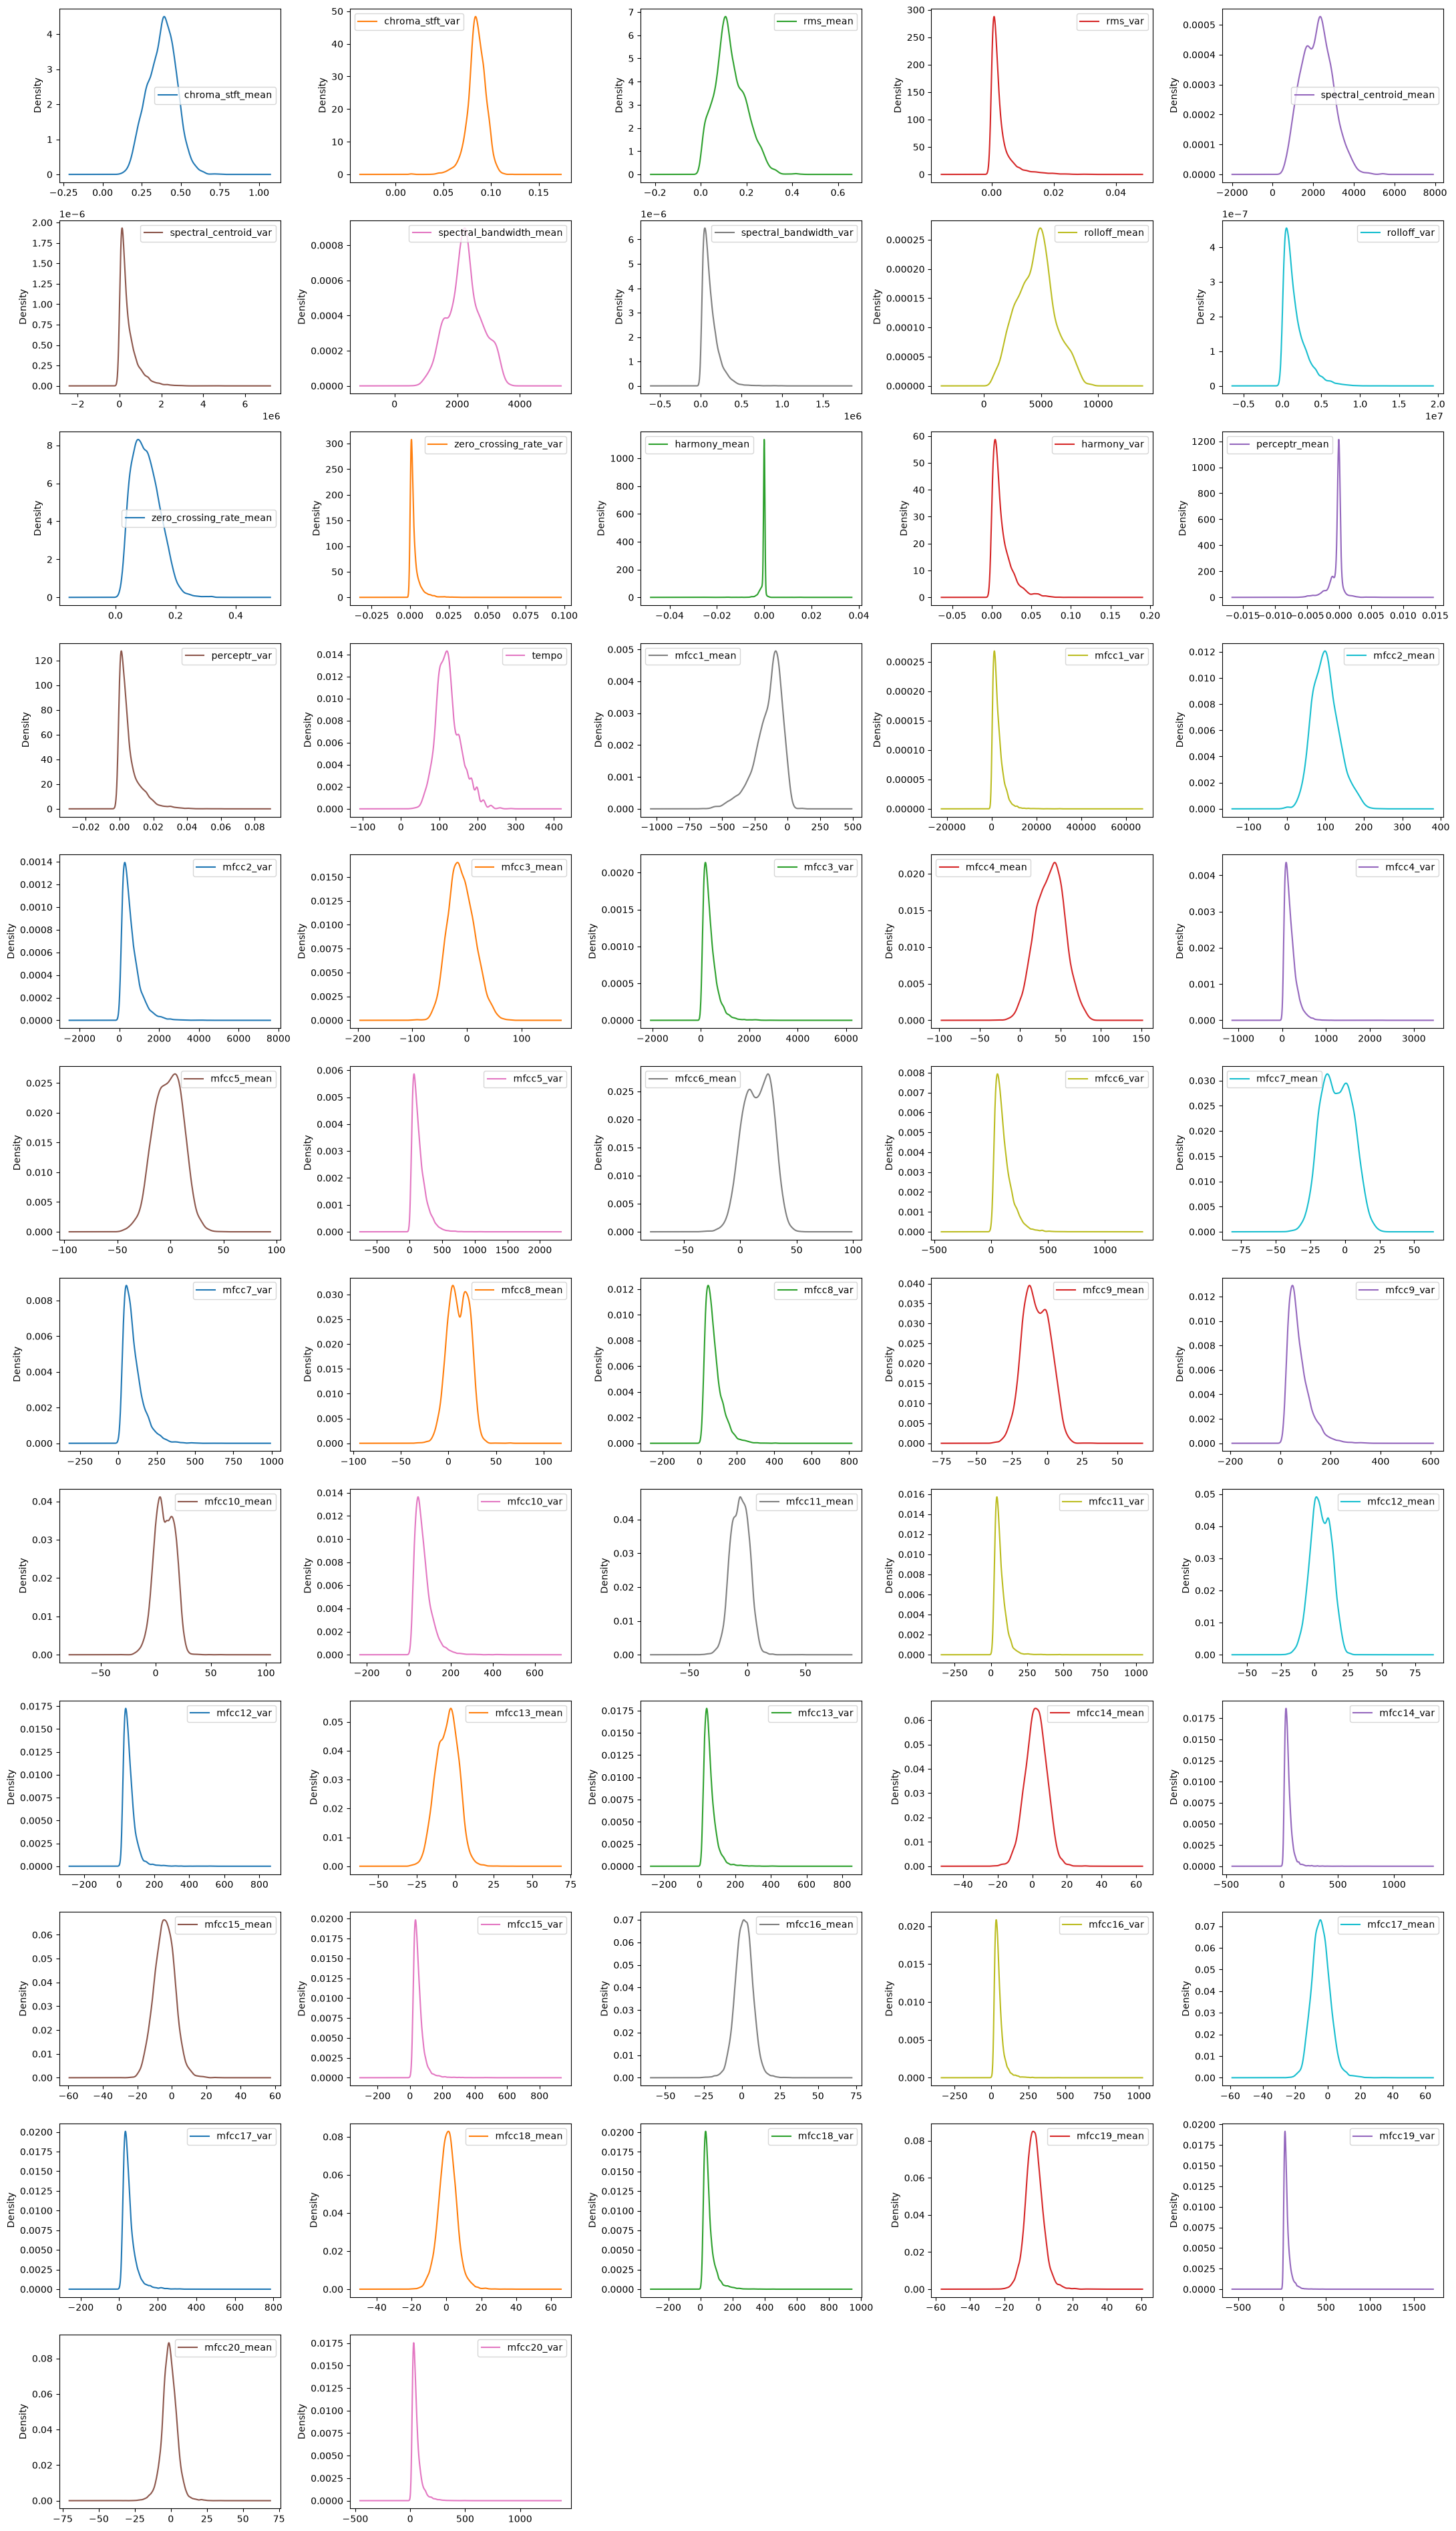

In [8]:
features.plot(kind="kde", subplots=True, layout=(12, 5), figsize=(22, 38), sharex=False)
plt.tight_layout()
plt.show()

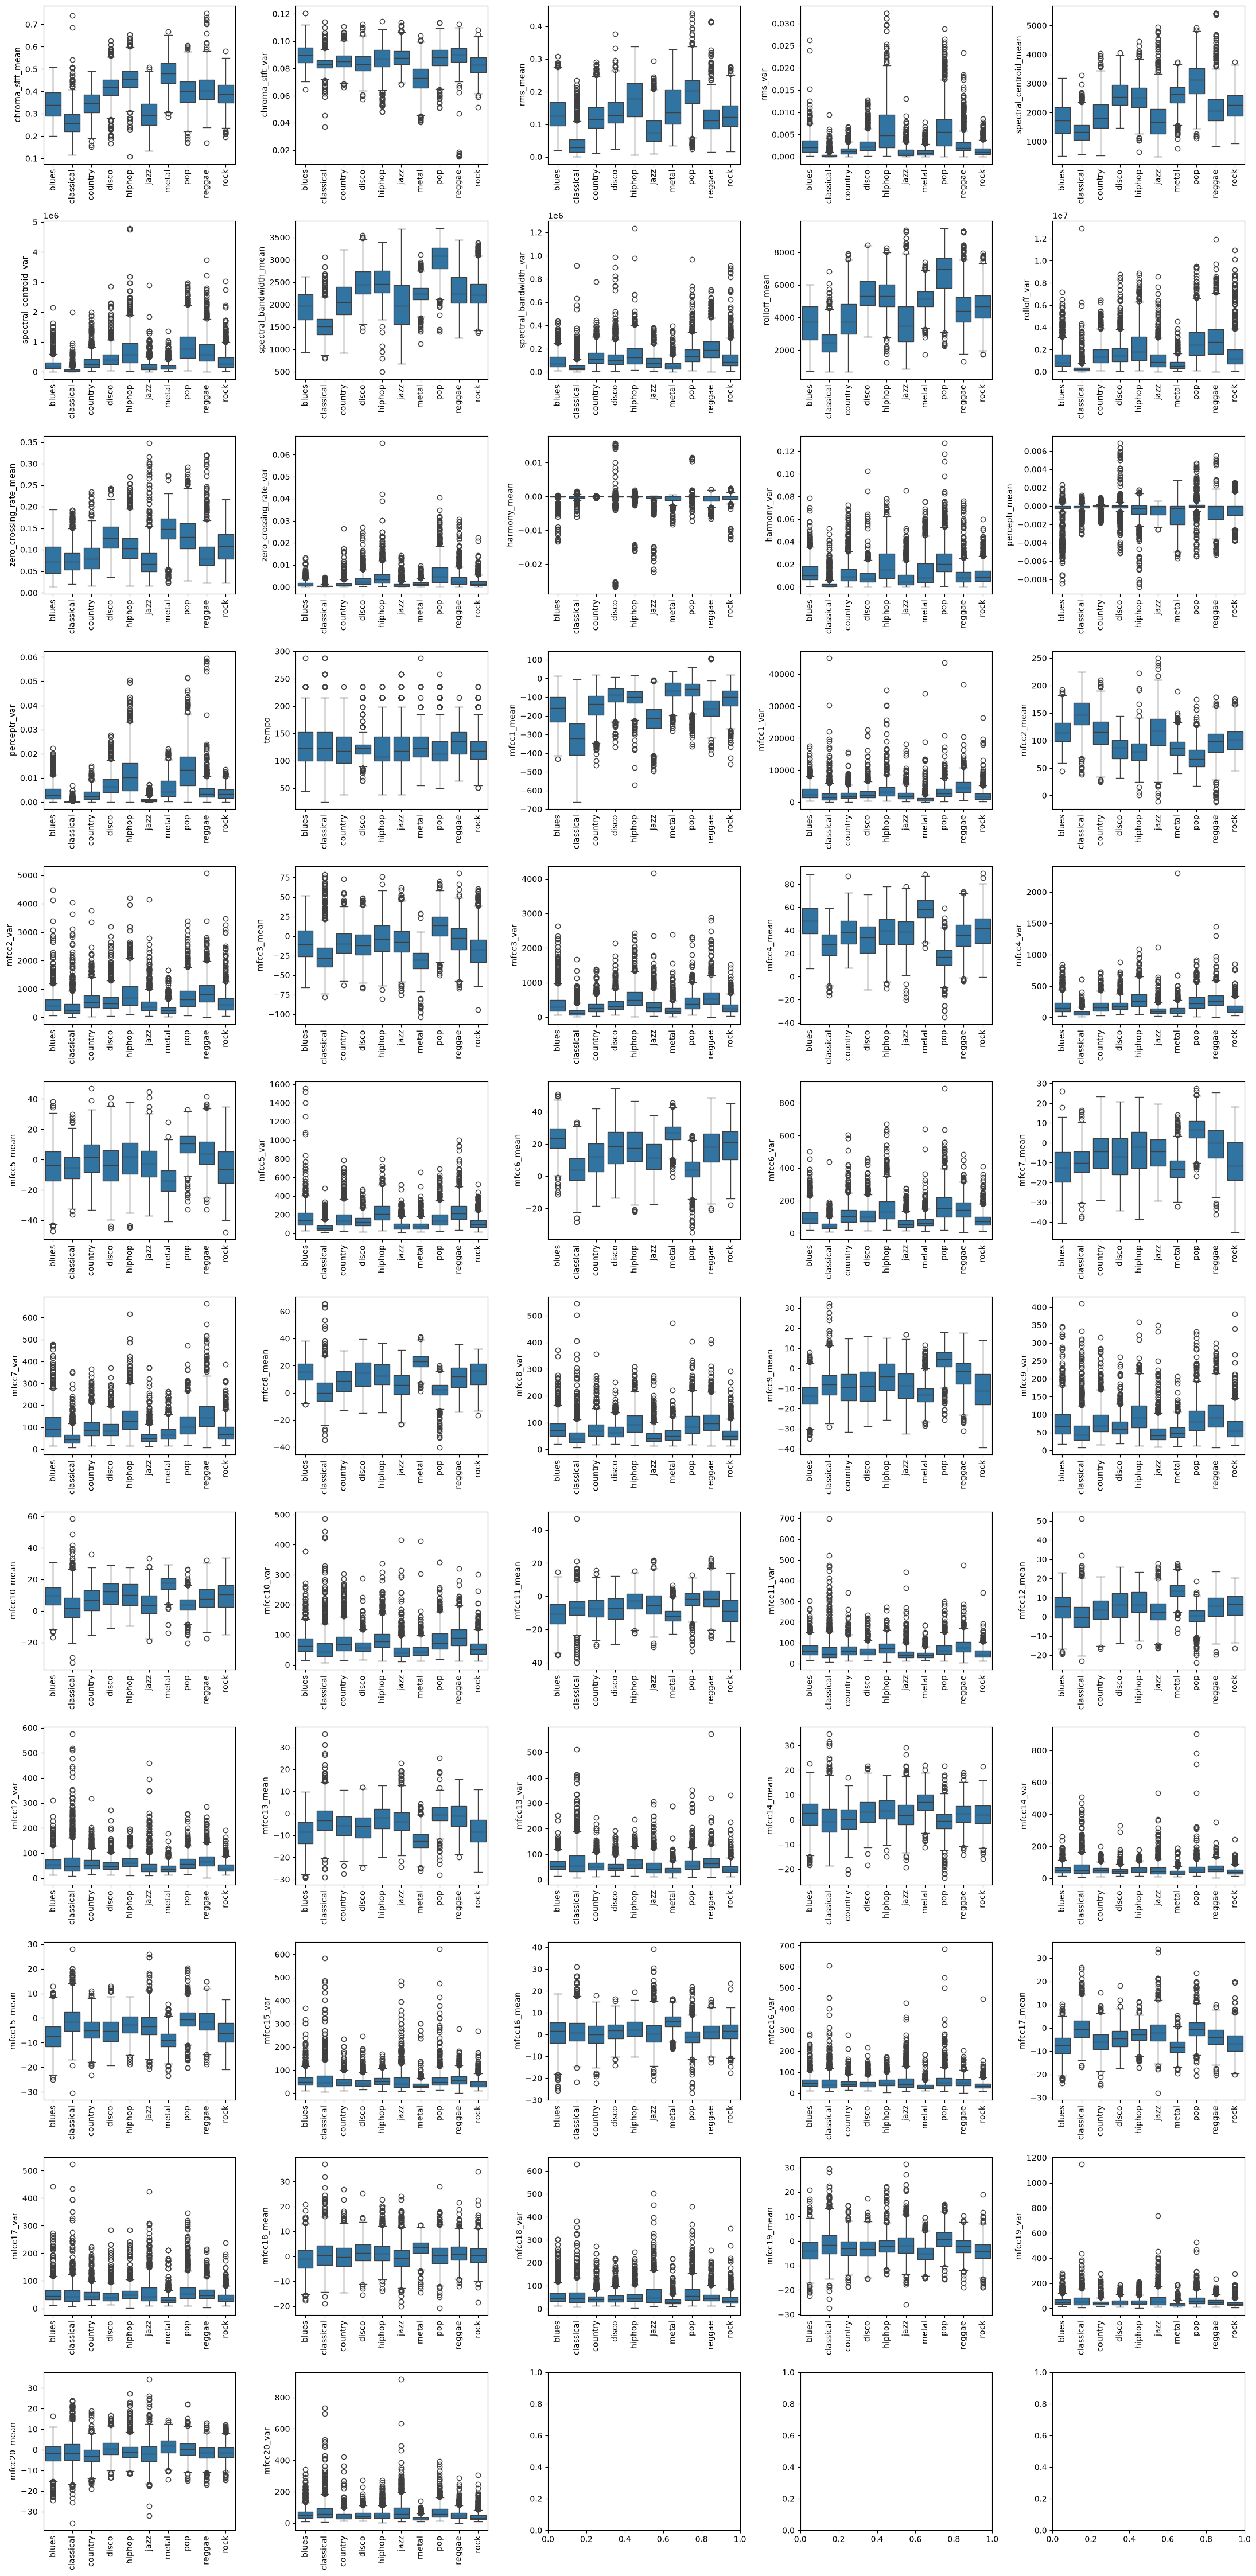

In [9]:
features = df.drop(columns=["song_id", "label", "length"])

fig, axes = plt.subplots(12, 5, figsize=(22, 45))
for ax, col in zip(axes.ravel(), features.columns):
    sns.boxplot(data=df, x="label", y=col, ax=ax)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

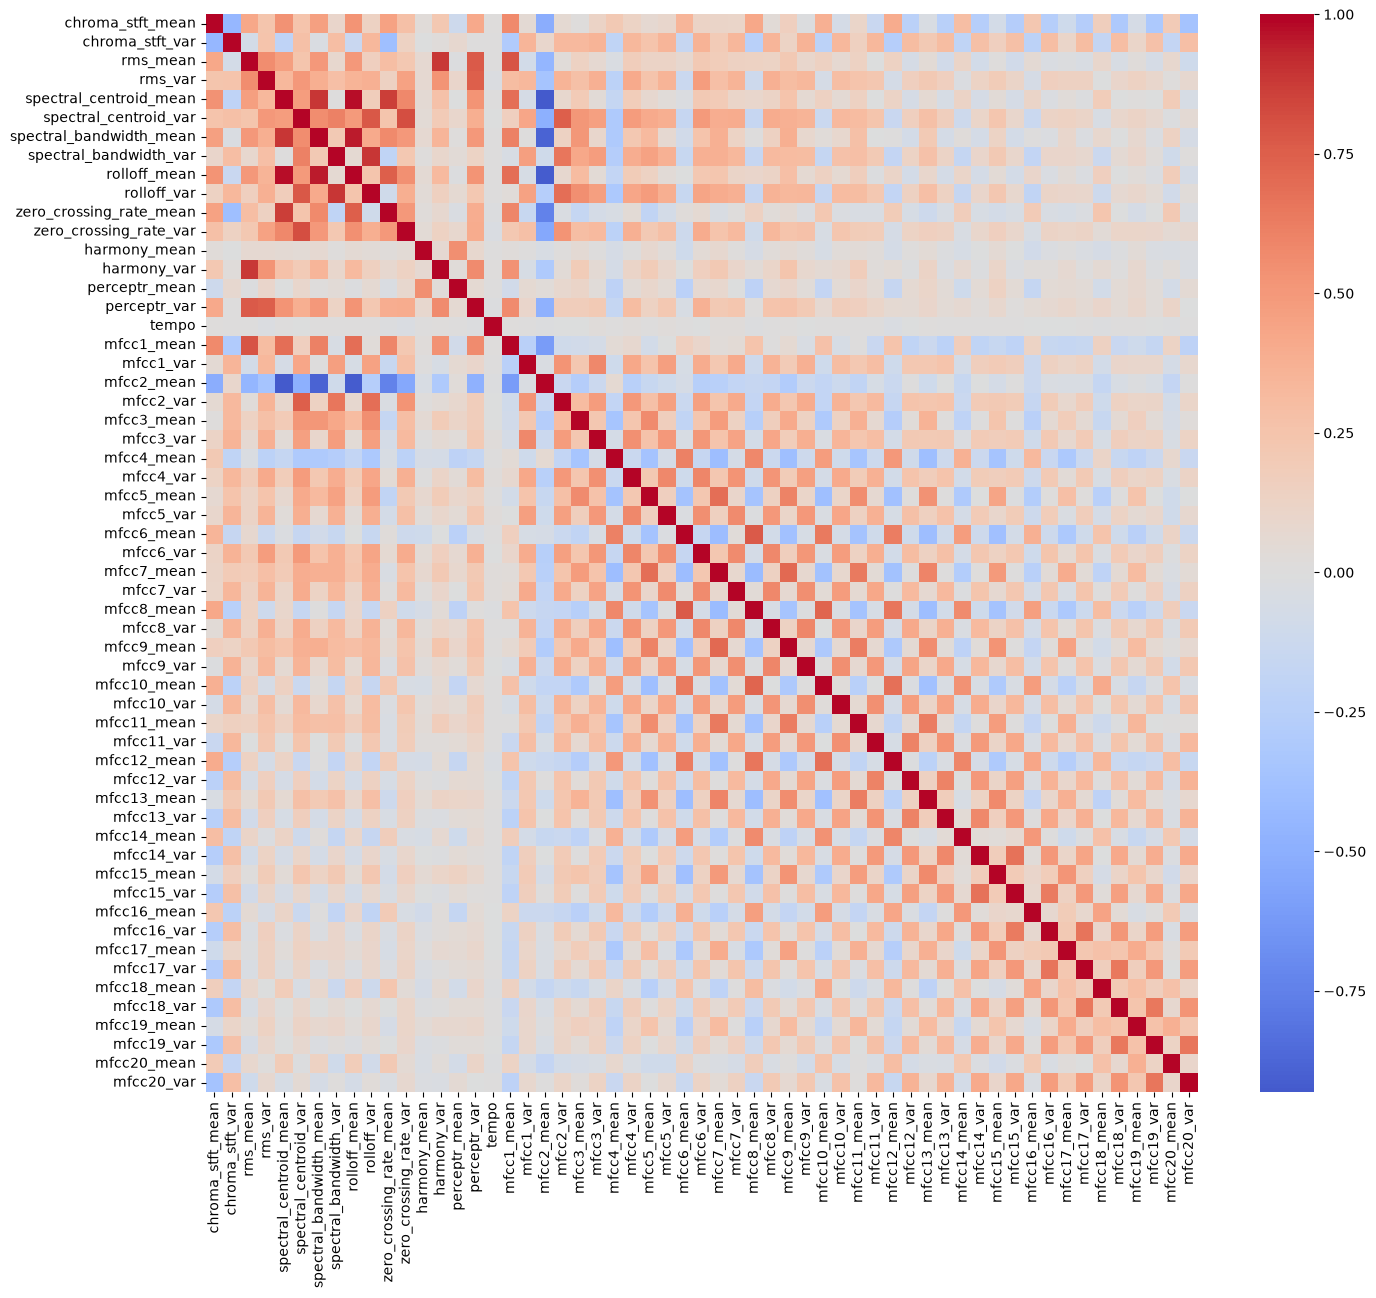

In [10]:
features = df.drop(columns=["song_id", "label", "length"])

plt.figure(figsize=(16, 14))
sns.heatmap(features.corr(), cmap="coolwarm", center=0)
plt.show()

In [11]:
features = df.drop(columns=["song_id", "label", "length"])

Q1 = features.quantile(0.25)
Q3 = features.quantile(0.75)
IQR = Q3 - Q1

outliers = ((features < Q1 - 1.5 * IQR) | (features > Q3 + 1.5 * IQR)).sum()
outliers.sort_values(ascending=False).head(15)
(outliers / len(features) * 100).sort_values(ascending=False).head(15)

harmony_mean              22.041880
perceptr_mean             15.339144
rms_var                    9.167418
zero_crossing_rate_var     9.067228
mfcc20_var                 6.772868
mfcc19_var                 6.562469
mfcc18_var                 6.372107
perceptr_var               6.301974
spectral_centroid_var      5.971346
mfcc17_var                 5.841098
mfcc16_var                 5.620679
harmony_var                5.360184
mfcc15_var                 5.209899
mfcc13_var                 4.749023
mfcc14_var                 4.688909
dtype: float64

In [12]:
y = df["label"]
groups = df["song_id"]
X = df.drop(columns=["label", "song_id", "length"])

print(X.shape)
print(y.shape)

(9981, 57)
(9981,)


In [13]:
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(sgkf.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(X_train.shape, X_test.shape)
print("Songs in both sets:", len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))
print(y_test.value_counts())

(7992, 57) (1989, 57)
Songs in both sets: 0
label
blues        200
classical    200
country      200
disco        200
metal        200
pop          200
reggae       200
rock         200
hiphop       199
jazz         190
Name: count, dtype: int64


In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled.mean().round(3), X_train_scaled.std().round(3))
print(X_test_scaled.mean().round(3), X_test_scaled.std().round(3))

-0.0 1.0
0.017 1.005


In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

train_pred = model.predict(X_train_scaled)
test_pred = model.predict(X_test_scaled)

print("Train accuracy:", accuracy_score(y_train, train_pred))
print("Test accuracy: ", accuracy_score(y_test, test_pred))

Train accuracy: 0.7516266266266266
Test accuracy:  0.6465560583207642


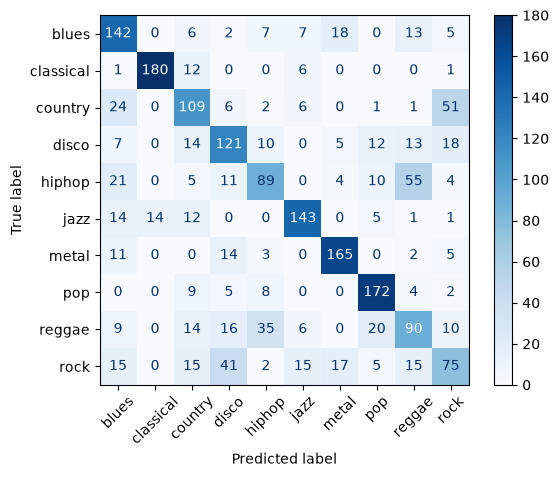

              precision    recall  f1-score   support

       blues       0.58      0.71      0.64       200
   classical       0.93      0.90      0.91       200
     country       0.56      0.55      0.55       200
       disco       0.56      0.60      0.58       200
      hiphop       0.57      0.45      0.50       199
        jazz       0.78      0.75      0.77       190
       metal       0.79      0.82      0.81       200
         pop       0.76      0.86      0.81       200
      reggae       0.46      0.45      0.46       200
        rock       0.44      0.38      0.40       200

    accuracy                           0.65      1989
   macro avg       0.64      0.65      0.64      1989
weighted avg       0.64      0.65      0.64      1989



In [17]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

ConfusionMatrixDisplay.from_predictions(y_test, test_pred, xticks_rotation=45, cmap="Blues")
plt.show()

print(classification_report(y_test, test_pred))

In [18]:
from sklearn.preprocessing import PowerTransformer

pt = PowerTransformer()
X_train_pt = pt.fit_transform(X_train)
X_test_pt = pt.transform(X_test)

model2 = LogisticRegression(max_iter=1000)
model2.fit(X_train_pt, y_train)

print("Train accuracy:", accuracy_score(y_train, model2.predict(X_train_pt)))
print("Test accuracy: ", accuracy_score(y_test, model2.predict(X_test_pt)))

Train accuracy: 0.7565065065065065
Test accuracy:  0.6510809451985923


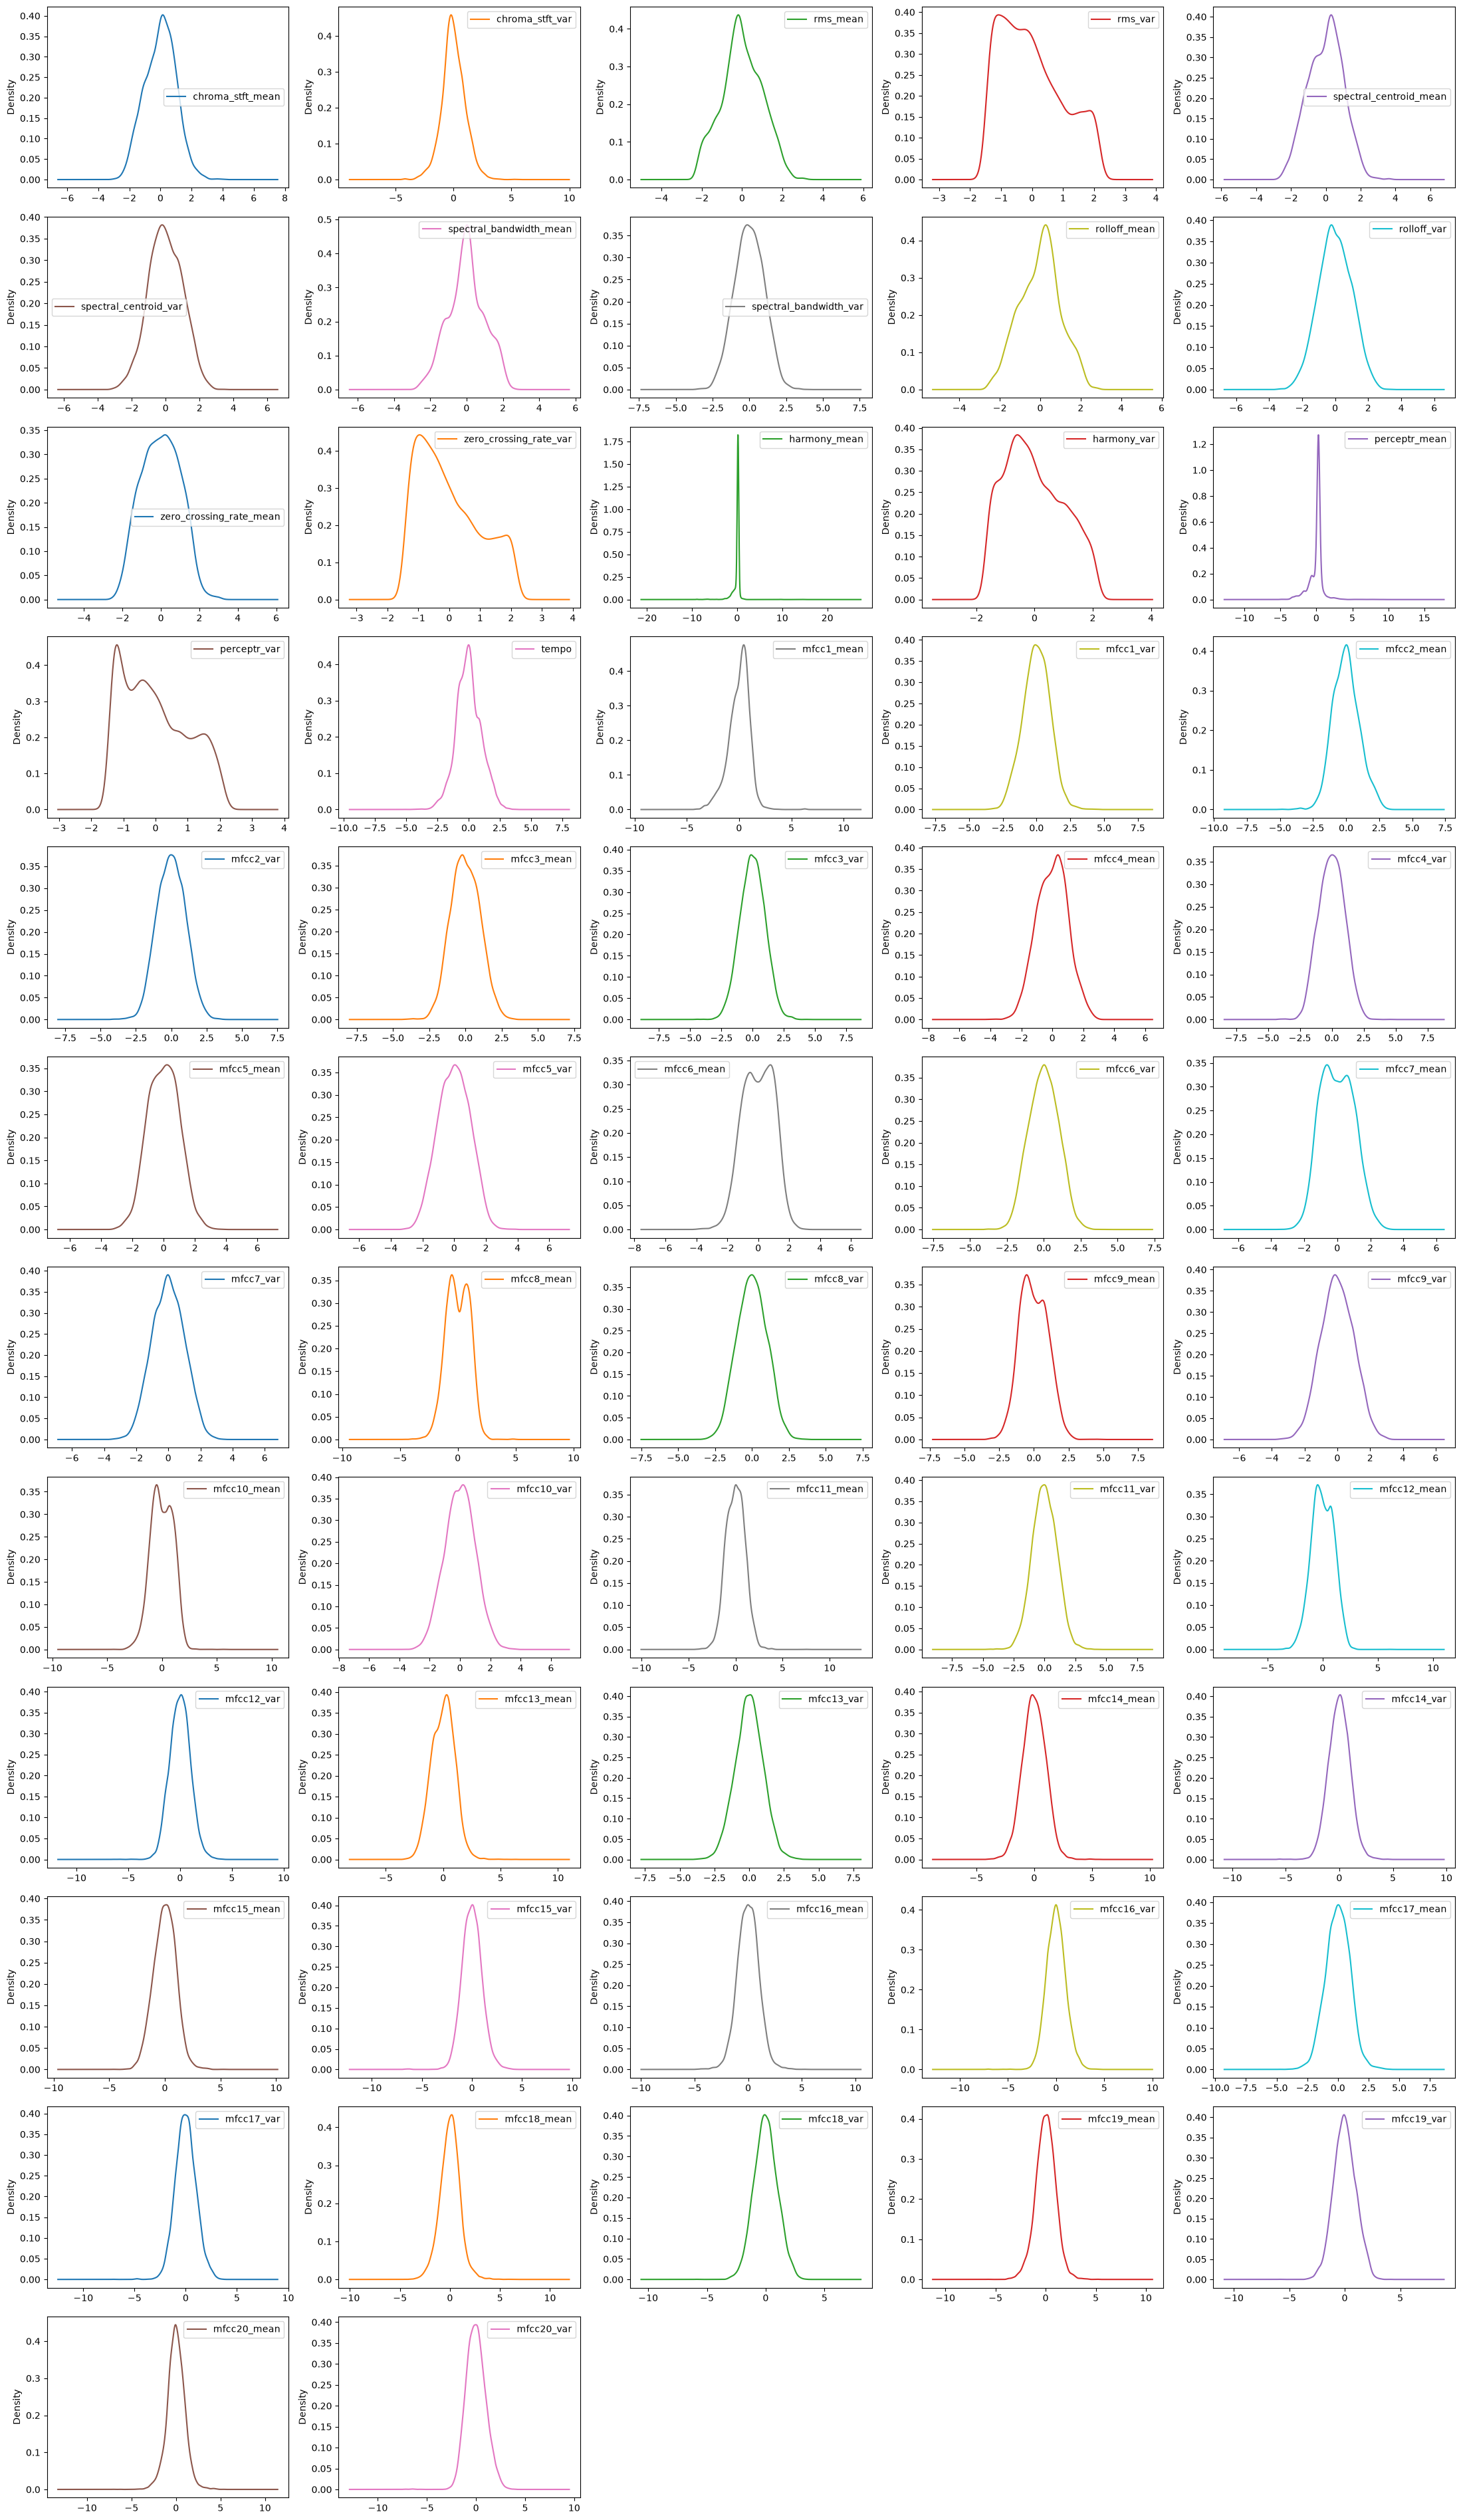

In [20]:
X_train_pt_df = pd.DataFrame(X_train_pt, columns=X.columns)

X_train_pt_df.plot(kind="kde", subplots=True, layout=(12, 5), figsize=(22, 38), sharex=False)
plt.tight_layout()
plt.show()

In [21]:
lo = X_train.quantile(0.01)
hi = X_train.quantile(0.99)

X_train_c = X_train.clip(lo, hi, axis=1)
X_test_c = X_test.clip(lo, hi, axis=1)

pt2 = PowerTransformer()
X_train_c_pt = pt2.fit_transform(X_train_c)
X_test_c_pt = pt2.transform(X_test_c)

model4 = LogisticRegression(max_iter=1000)
model4.fit(X_train_c_pt, y_train)
print("Test accuracy:", accuracy_score(y_test, model4.predict(X_test_c_pt)))

Test accuracy: 0.6591251885369532


In [23]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train_pt)
X_test_poly = poly.transform(X_test_pt)

sc = StandardScaler()
X_train_poly = sc.fit_transform(X_train_poly)
X_test_poly = sc.transform(X_test_poly)

model_poly = LogisticRegression(max_iter=2000)
model_poly.fit(X_train_poly, y_train)

print("Train accuracy:", accuracy_score(y_train, model_poly.predict(X_train_poly)))
print("Test accuracy: ", accuracy_score(y_test, model_poly.predict(X_test_poly)))

Train accuracy: 1.0
Test accuracy:  0.6691804927099044


In [24]:
for C in [0.0005, 0.002, 0.01]:
    m = LogisticRegression(C=C, max_iter=2000)
    m.fit(X_train_poly, y_train)
    print(f"C={C}  train: {accuracy_score(y_train, m.predict(X_train_poly)):.3f}  "
          f"test: {accuracy_score(y_test, m.predict(X_test_poly)):.3f}")

C=0.0005  train: 0.838  test: 0.667
C=0.002  train: 0.918  test: 0.680
C=0.01  train: 0.980  test: 0.683


In [13]:
best = LogisticRegression(C=0.01, max_iter=2000)
best.fit(X_train_poly, y_train)

proba = pd.DataFrame(best.predict_proba(X_test_poly), columns=best.classes_)
proba["song"] = groups.iloc[test_idx].values

song_proba = proba.groupby("song").mean()
song_pred = song_proba.idxmax(axis=1)
song_true = y_test.groupby(groups.iloc[test_idx].values).first().loc[song_pred.index]

print("Songs in test set:", len(song_pred))
print("Song-level accuracy:", accuracy_score(song_true, song_pred))

Songs in test set: 199
Song-level accuracy: 0.7587939698492462


In [10]:
from sklearn.svm import SVC

svm = SVC(kernel="rbf", C=10, gamma="scale")
svm.fit(X_train_pt, y_train)

print("Train accuracy:", accuracy_score(y_train, svm.predict(X_train_pt)))
print("Test accuracy (segment):", accuracy_score(y_test, svm.predict(X_test_pt)))

scores = pd.DataFrame(svm.decision_function(X_test_pt), columns=svm.classes_)
scores["song"] = groups.iloc[test_idx].values
song_pred = scores.groupby("song").mean().idxmax(axis=1)
song_true = y_test.groupby(groups.iloc[test_idx].values).first().loc[song_pred.index]

print("Test accuracy (song):", accuracy_score(song_true, song_pred))

Train accuracy: 0.9997497497497497
Test accuracy (segment): 0.722473604826546
Test accuracy (song): 0.7638190954773869


In [25]:
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PowerTransformer

groups_train = groups.iloc[train_idx]

pipe = make_pipeline(PowerTransformer(), SVC(kernel="rbf"))
grid = {"svc__C": [1, 3, 10], "svc__gamma": [0.001, 0.003, "scale"]}

search = GridSearchCV(
    pipe, grid,
    cv=StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42),
    scoring="accuracy", n_jobs=-1, verbose=1,
)
search.fit(X_train, y_train, groups=groups_train)

print(search.best_params_)
print("CV accuracy:", round(search.best_score_, 3))
pd.DataFrame(search.cv_results_)[["param_svc__C", "param_svc__gamma", "mean_test_score"]] \
    .sort_values("mean_test_score", ascending=False)

Fitting 3 folds for each of 9 candidates, totalling 27 fits
{'svc__C': 3, 'svc__gamma': 'scale'}
CV accuracy: 0.717


,param_svc__C,param_svc__gamma,mean_test_score
5,3,scale,0.717461
8,10,scale,0.716835
2,1,scale,0.710953
7,10,0.003,0.700698
4,3,0.003,0.690560
6,10,0.001,0.678923
1,1,0.003,0.667913
3,3,0.001,0.658278
0,1,0.001,0.627372


In [26]:
grid = {"svc__C": [3, 10], "svc__gamma": [0.0175, 0.03, 0.06, 0.1]}

search = GridSearchCV(
    pipe, grid,
    cv=StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42),
    scoring="accuracy", n_jobs=-1, verbose=1,
)
search.fit(X_train, y_train, groups=groups_train)

print(search.best_params_)
pd.DataFrame(search.cv_results_)[["param_svc__C", "param_svc__gamma", "mean_test_score"]] \
    .sort_values("mean_test_score", ascending=False)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
{'svc__C': 3, 'svc__gamma': 0.03}


,param_svc__C,param_svc__gamma,mean_test_score
1,3,0.0300,0.718708
5,10,0.0300,0.717459
0,3,0.0175,0.717335
4,10,0.0175,0.716835
6,10,0.0600,0.695936
2,3,0.0600,0.695686
3,3,0.1000,0.619729
7,10,0.1000,0.619729


In [27]:
final = make_pipeline(PowerTransformer(), SVC(kernel="rbf", C=3, gamma=0.03))
final.fit(X_train, y_train)

print("Segment accuracy:", accuracy_score(y_test, final.predict(X_test)))

scores = pd.DataFrame(final.decision_function(X_test), columns=final.classes_)
scores["song"] = groups.iloc[test_idx].values
song_pred = scores.groupby("song").mean().idxmax(axis=1)
song_true = y_test.groupby(groups.iloc[test_idx].values).first().loc[song_pred.index]
print("Song accuracy:", accuracy_score(song_true, song_pred))

Segment accuracy: 0.726998491704374
Song accuracy: 0.7638190954773869


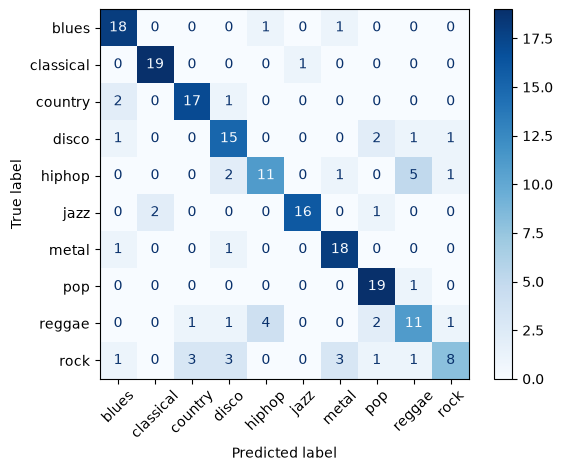

              precision    recall  f1-score   support

       blues       0.78      0.90      0.84        20
   classical       0.90      0.95      0.93        20
     country       0.81      0.85      0.83        20
       disco       0.65      0.75      0.70        20
      hiphop       0.69      0.55      0.61        20
        jazz       0.94      0.84      0.89        19
       metal       0.78      0.90      0.84        20
         pop       0.76      0.95      0.84        20
      reggae       0.58      0.55      0.56        20
        rock       0.73      0.40      0.52        20

    accuracy                           0.76       199
   macro avg       0.76      0.76      0.76       199
weighted avg       0.76      0.76      0.75       199



In [28]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

ConfusionMatrixDisplay.from_predictions(song_true, song_pred, xticks_rotation=45, cmap="Blues")
plt.show()
print(classification_report(song_true, song_pred))

In [29]:
from sklearn.decomposition import PCA

pipe_pca = make_pipeline(PowerTransformer(), PCA(), SVC(kernel="rbf", C=3, gamma="scale"))
grid = {"pca__n_components": [10, 20, 30, 40, 57]}

search = GridSearchCV(
    pipe_pca, grid,
    cv=StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42),
    scoring="accuracy", n_jobs=-1,
)
search.fit(X_train, y_train, groups=groups_train)

pd.DataFrame(search.cv_results_)[["param_pca__n_components", "mean_test_score"]]

,param_pca__n_components,mean_test_score
0,10,0.597584
1,20,0.656774
2,30,0.683428
3,40,0.696190
4,57,0.717461


In [30]:
pipe_poly = make_pipeline(PowerTransformer(), SVC(kernel="poly", coef0=1, gamma="scale")) #polynomial kernel svm
grid = {"svc__degree": [2, 3], "svc__C": [1, 3]}

search = GridSearchCV(
    pipe_poly, grid,
    cv=StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42),
    scoring="accuracy", n_jobs=-1, verbose=1,
)
search.fit(X_train, y_train, groups=groups_train)

pd.DataFrame(search.cv_results_)[["param_svc__degree", "param_svc__C", "mean_test_score"]] \
    .sort_values("mean_test_score", ascending=False)

Fitting 3 folds for each of 4 candidates, totalling 12 fits


,param_svc__degree,param_svc__C,mean_test_score
1,3,1,0.708832
3,3,3,0.708584
2,2,3,0.706203
0,2,1,0.703955


In [24]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
seg_scores, song_scores = [], []

for fold, (tr, te) in enumerate(cv.split(X, y, groups), start=1):
    m = make_pipeline(PowerTransformer(), SVC(kernel="rbf", C=3, gamma=0.03))
    m.fit(X.iloc[tr], y.iloc[tr])

    seg = accuracy_score(y.iloc[te], m.predict(X.iloc[te]))

    s = pd.DataFrame(m.decision_function(X.iloc[te]), columns=m.classes_)
    s["song"] = groups.iloc[te].values
    pred = s.groupby("song").mean().idxmax(axis=1)
    true = y.iloc[te].groupby(groups.iloc[te].values).first().loc[pred.index]
    song = accuracy_score(true, pred)

    seg_scores.append(seg)
    song_scores.append(song)
    print(f"Fold {fold}: segment={seg:.3f}  song={song:.3f}")

print(f"\nSegment-level: {np.mean(seg_scores):.3f} +/- {np.std(seg_scores):.3f}")
print(f"Song-level:    {np.mean(song_scores):.3f} +/- {np.std(song_scores):.3f}")

Fold 1: segment=0.727  song=0.764
Fold 2: segment=0.776  song=0.840
Fold 3: segment=0.738  song=0.810
Fold 4: segment=0.735  song=0.765
Fold 5: segment=0.728  song=0.790

Segment-level: 0.741 +/- 0.018
Song-level:    0.794 +/- 0.029
